# Field reconstruction and calibration
An orthonormal $64\times8$ spatial DCT basis and a changing rank-three coefficient subspace generate noisy $8\times8$ fields. Passive measurements use unknown Gaussian coefficients; known calibration patterns use a separate conditional protocol. Supplied frame motion accounts for half the physical motion.

Mean and modal estimates share Bingham parameters. Passive benchmarks are full-observation GROUSE, EW covariance PCA, and rolling PCA with equal candidate counts and independent validation trajectories. Reconstruction uses the current corrected posterior as in Eq. (45). Oracle projection is a reference. See `benchmarks/case2/README.md` for references. Eight trajectories are a reproducible pilot, not a precise calibration study.

In [1]:
from pathlib import Path
import sys, os, json
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from lib.validation import require_gate
print('Theory gate:',require_gate(ROOT)['status'])
from lib.plotting import plt,save
from lib.reporting import run_or_load,coverage_table,error_curve
import numpy as np
import pandas as pd
from IPython.display import display
OUT=ROOT/'results'
# Set refresh=True to resimulate; cached tables are verified against source/config hashes.
config=dict(repeats=8,T=72,draws=6000,burnin=2500,max_draws=24000,max_burnin=8000)

result=run_or_load(ROOT,'case2',dict(seed=2718,**config))
m=result['metrics'];c=result['calibration'];noise=result['noise'];display(result['config'])

Theory gate: passed


case2: loading verified simulation tables


{'seed': 2718,
 'repeats': 8,
 'T': 72,
 'draws': 6000,
 'burnin': 2500,
 'n': 8,
 'k': 3,
 'd': 64,
 's': 0.2,
 'tau2': 1.5,
 'checkpoints': [12, 36, 72],
 'max_draws': 24000,
 'max_burnin': 8000,
 'known_motion_fraction': 0.5,
 'nominal_mass': 0.95,
 'validation_candidates': 3,
 'spatial_basis': 'Eight low-frequency separable DCT-II modes on an 8x8 grid',
 'calibration_input_rank': 'Rank of supplied-frame transported preassigned inputs',
 'coverage_distribution': 'Independent Gaussian-QR initial subspaces, Gaussian skew drift paths, and Gaussian observations',
 'coverage_guaranteed': False,
 'noise_fit_ascent_verified': False,
 'score_method': 'Prior Monte Carlo log-mean-exp, with importance ESS and chain discrepancy'}

## Reconstruction and mismatch
Errors are squared clean-field errors in all 64 coordinates. The DCT lift is isometric, so coefficient and field errors agree. Unequal powers and sparse corruptions violate the fitted isotropic Gaussian model.

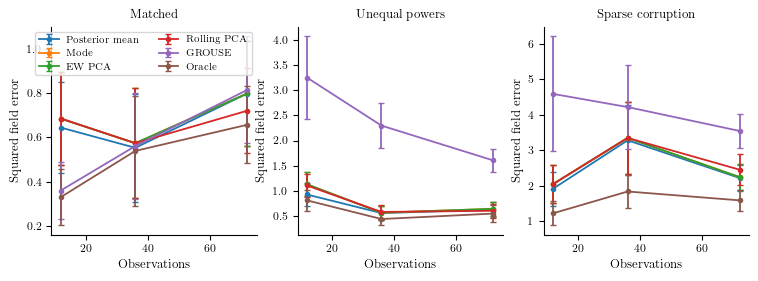

mean       std  count
scenario          method                                   
Matched           EW PCA          0.798064  0.674097      8
                  GROUSE          0.814070  0.681799      8
                  Mode            0.798064  0.674097      8
                  Oracle          0.657018  0.491007      8
                  Posterior mean  0.797867  0.668895      8
                  Rolling PCA     0.720331  0.541698      8
Sparse corruption EW PCA          2.245619  1.010239      8
                  GROUSE          3.544295  1.384297      8
                  Mode            2.245619  1.010239      8
                  Oracle          1.591154  0.858507      8
                  Posterior mean  2.220881  1.024672      8
                  Rolling PCA     2.454236  1.208633      8
Unequal powers    EW PCA          0.644547  0.394583      8
                  GROUSE          1.605028  0.621244      8
                  Mode            0.644547  0.394583      8
                  Oracle          0.549981  0.463607      8
                  Posterior mean  0.630485  0.399751      8
                  Rolling PCA     0.605958  0.381743      8

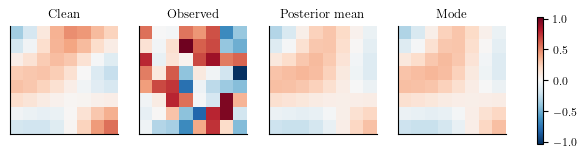

In [2]:
fig,axs=plt.subplots(1,3,figsize=(9,2.7))
for ax,scenario in zip(axs,['Matched','Unequal powers','Sparse corruption']):
    error_curve(ax,m[m.scenario==scenario],'field_squared_error',['Posterior mean','Mode','EW PCA','Rolling PCA','GROUSE','Oracle'])
    ax.set_title(scenario);ax.set_ylabel('Squared field error')
axs[0].legend(ncol=2);save(fig,OUT/'field_reconstruction');plt.show()
final=m[m.t==config['T']]
display(final.groupby(['scenario','method']).field_squared_error.agg(['mean','std','count']))
f=result['fields'];images=[f.clean,f.observed,f.posterior_mean,f['mode']]
vmax=max(max(abs(v)) for v in images)
fig,axs=plt.subplots(1,4,figsize=(8,2.2))
for ax,data,title in zip(axs,images,['Clean','Observed','Posterior mean','Mode']):
    im=ax.imshow(np.asarray(data).reshape(8,8),cmap='RdBu_r',vmin=-vmax,vmax=vmax);ax.set_title(title);ax.set_xticks([]);ax.set_yticks([])
fig.colorbar(im,ax=axs,shrink=.75);save(fig,OUT/'field_maps');plt.show()


## Known calibration patterns
Preassigned patterns are transported by the supplied frame so their transported rank stays at 6, 7, or 8. They never use the hidden subspace. Physical drift remains, so these runs are not a common-subspace proof of Proposition 4; the general notebook supplies the controlled identifiability counterexamples.

Eq. (30) predicts posterior response risk and the nonnegative modal excess risk. Realized errors against one true trajectory need not respect this ordering.

mean_squared_error  modal_squared_error  posterior_risk  \
input_rank t                                                             
6          12            0.378685             0.462135        0.444291   
           36            0.088119             0.087994        0.170589   
           72            0.119547             0.121394        0.081139   
7          12            0.371504             0.410780        0.434309   
           36            0.110436             0.120479        0.162627   
           72            0.098243             0.100550        0.074654   
8          12            0.240145             0.240717        0.371858   
           36            0.086619             0.088463        0.119607   
           72            0.081143             0.082843        0.077049   

               modal_excess_risk  
input_rank t                      
6          12           0.089745  
           36           0.009331  
           72           0.002059  
7          12           0.102610  
           36           0.008155  
           72           0.001588  
8          12           0.066633  
           36           0.004112  
           72           0.001668

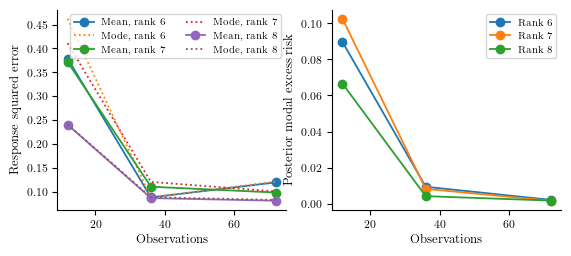

In [3]:
display(c.groupby(['input_rank','t'])[['mean_squared_error','modal_squared_error','posterior_risk','modal_excess_risk']].mean())
fig,axs=plt.subplots(1,2,figsize=(6.5,2.6))
for rank,g in c.groupby('input_rank'):
    mean=g.groupby('t')[['mean_squared_error','modal_squared_error','posterior_risk','modal_excess_risk']].mean()
    axs[0].plot(mean.index,mean.mean_squared_error,'o-',label=rf'Mean, rank {rank}')
    axs[0].plot(mean.index,mean.modal_squared_error,':',label=rf'Mode, rank {rank}')
    axs[1].plot(mean.index,mean.modal_excess_risk,'o-',label=rf'Rank {rank}')
for ax in axs:ax.set_xlabel('Observations')
axs[0].set_ylabel('Response squared error');axs[1].set_ylabel('Posterior modal excess risk');axs[0].legend(ncol=2);axs[1].legend()
save(fig,OUT/'field_calibration');plt.show()
assert c.modal_excess_risk.min()>=0


## Noise estimation and predictive scores
These are separate runs with eight stored priors, fits at predeclared times, and two EM iterations. Predictions are scored before fitting or correcting the incoming measurement. Historical priors stay fixed within each fit, and no historical observation is corrected again.

High-dimensional sampled E-steps do not have a verified ascent guarantee here; the general notebook verifies ascent using deterministic references. Window residual and uncertainty diagnostics below use a common final-candidate E-step target. Their sum is the expected residual statistic, rather than a claim to equal the preceding finite EM update. Only the eight observed coefficient coordinates are used for fitting; the 56 complementary pure-noise coordinates are excluded.

,protocol,t,s,tau2,true_s,true_tau2,naive_residual_variance,uncertainty_variance,expected_residual_variance,residual_diagnostic_target,fit_seconds,mean_evaluations,accepted,numerical_ascent_verified,minimum_ess,predictive_log_score,score_chain_difference,score_importance_ess,score_sampler_ess,score_seconds
0,Passive,24,0.268482,0.991321,0.2,1.5,NaN,NaN,NaN,Frozen window evaluated at the accepted final ...,3.628784,16,2,False,36.578213,-7.661798,0.012346,1953.201465,84.079773,0.534681
1,Passive,48,0.127932,2.309874,0.2,1.5,NaN,NaN,NaN,Frozen window evaluated at the accepted final ...,5.991850,16,2,False,23.719823,-8.598801,0.012969,1768.367009,34.965731,2.636009
2,Passive,72,0.228451,1.083196,0.2,1.5,NaN,NaN,NaN,Frozen window evaluated at the accepted final ...,9.626058,16,2,False,21.995372,-7.903061,0.019493,1836.691656,33.135310,1.003002
3,Calibration,24,0.295238,NaN,0.2,NaN,0.226805,0.057932,0.284737,Frozen window evaluated at the accepted final ...,15.154396,16,2,False,22.086918,-6.533855,0.038457,1577.208598,57.251182,1.698485
4,Calibration,48,0.169952,NaN,0.2,NaN,0.147913,0.019185,0.167098,Frozen window evaluated at the accepted final ...,5.219710,16,2,False,26.758641,-4.176687,0.071518,1729.190883,74.200673,0.617992
5,Calibration,72,0.196674,NaN,0.2,NaN,0.186115,0.010739,0.196854,Frozen window evaluated at the accepted final ...,5.734462,16,2,False,27.430202,-3.326567,0.027570,1628.957870,87.112925,0.422977


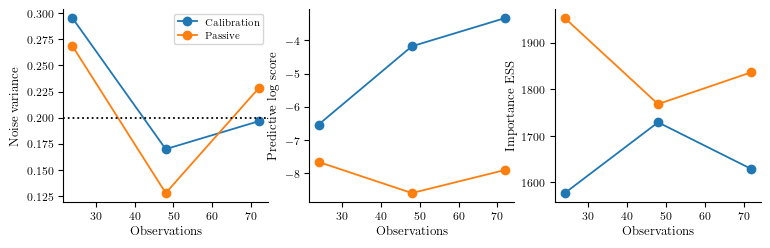

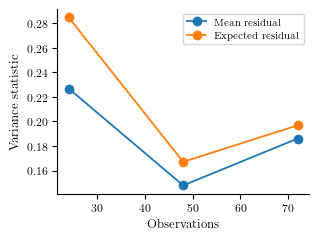

,protocol,t,score_importance_ess,score_sampler_ess,score_chain_difference,minimum_ess,numerical_ascent_verified
0,Passive,24,1953.201465,84.079773,0.012346,36.578213,False
1,Passive,48,1768.367009,34.965731,0.012969,23.719823,False
2,Passive,72,1836.691656,33.135310,0.019493,21.995372,False
3,Calibration,24,1577.208598,57.251182,0.038457,22.086918,False
4,Calibration,48,1729.190883,74.200673,0.071518,26.758641,False
5,Calibration,72,1628.957870,87.112925,0.027570,27.430202,False


In [4]:
display(noise)
fig,axs=plt.subplots(1,3,figsize=(9,2.5))
for protocol,g in noise.groupby('protocol'):
    axs[0].plot(g.t,g.s,'o-',label=protocol)
    axs[1].plot(g.t,g.predictive_log_score,'o-',label=protocol)
    axs[2].plot(g.t,g.score_importance_ess,'o-',label=protocol)
axs[0].axhline(.2,color='k',ls=':');axs[0].set_ylabel('Noise variance');axs[1].set_ylabel('Predictive log score');axs[2].set_ylabel('Importance ESS')
for ax in axs:ax.set_xlabel('Observations')
axs[0].legend();save(fig,OUT/'field_noise');plt.show()
cal=noise[noise.protocol=='Calibration']
fig,ax=plt.subplots(figsize=(3.25,2.4));ax.plot(cal.t,cal.naive_residual_variance,'o-',label='Mean residual');ax.plot(cal.t,cal.expected_residual_variance,'o-',label='Expected residual');ax.set_xlabel('Observations');ax.set_ylabel('Variance statistic');ax.legend();save(fig,OUT/'field_noise_uncertainty');plt.show()
assert np.allclose(cal.expected_residual_variance,cal.naive_residual_variance+cal.uncertainty_variance)
# Finite-sample log-mean-exp scores have bias; importance and chain ESS differ.
display(noise[['protocol','t','score_importance_ess','score_sampler_ess','score_chain_difference','minimum_ess','numerical_ascent_verified']])


## Calibration, numerical accuracy, and runtime
Coverage below uses terminal repeated-trajectory observations. Wilson intervals reflect finite repetition count. Raw sampler failures are retained; they do not become evidence for calibrated posterior coverage. Field timings count cumulative tracking and posterior moment work, excluding the final matrix-vector reconstruction. Oracle timing is omitted.

,scenario,region,coverage,low,high,n
0,Matched,Ball,0.000,0.000000,0.324416,8
1,Matched,HPD,0.000,0.000000,0.324416,8
2,Sparse corruption,Ball,0.000,0.000000,0.324416,8
3,Sparse corruption,HPD,0.000,0.000000,0.324416,8
4,Unequal powers,Ball,0.875,0.529105,0.977583,8
5,Unequal powers,HPD,0.625,0.305738,0.863158,8


,pass_fraction,minimum_ess,largest_rhat,largest_mcse,moment_seconds
scenario,,,,,
Matched,1.0,93.070394,1.031737,0.011178,1.745202
Sparse corruption,1.0,54.246672,1.030609,0.017339,2.245338
Unequal powers,1.0,53.359387,1.035076,0.024855,2.152618


,decision_seconds,update_seconds
method,,
EW PCA,0.008033,0.008033
GROUSE,0.011851,0.011851
Mode,0.013465,0.013465
Oracle,0.000000,0.000000
Posterior mean,6.156623,0.013465
Rolling PCA,0.015415,0.015415


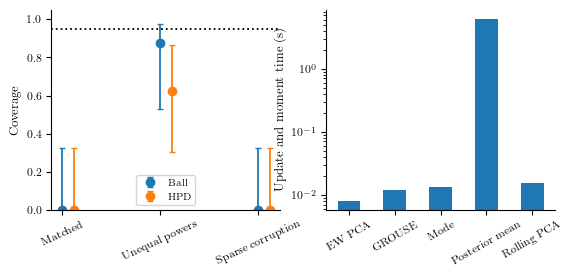

Failed passive sampling diagnostics: 0 of 72
Failed calibration sampling diagnostics: 0 of 72


,method,parameter,value,validation_loss,scenario
0,Bingham,beta,0.94,0.685179,Matched
1,Bingham,beta,0.98,0.623122,Matched
2,Bingham,beta,1.00,0.610690,Matched
3,EW PCA,beta,0.94,0.685179,Matched
4,EW PCA,beta,0.98,0.623122,Matched
5,EW PCA,beta,1.00,0.610690,Matched
6,Rolling PCA,window,12.00,0.896513,Matched
7,Rolling PCA,window,24.00,0.698990,Matched
8,Rolling PCA,window,48.00,0.612181,Matched
9,GROUSE,step,0.01,0.567917,Matched


In [5]:
p=final[final.method=='Posterior mean'];coverage=coverage_table(p);display(coverage)
diagnostics=m[m.method=='Posterior mean']
display(diagnostics.groupby('scenario').agg(pass_fraction=('sampling_ok','mean'),minimum_ess=('min_ess','min'),largest_rhat=('max_rhat','max'),largest_mcse=('max_mcse','max'),moment_seconds=('moment_seconds','mean')))
display(final.groupby('method')[['decision_seconds','update_seconds']].mean())
fig,axs=plt.subplots(1,2,figsize=(6.5,2.6))
scenarios=list(p.scenario.unique())
for i,(region,g) in enumerate(coverage.groupby('region')):
    g=g.set_index('scenario').reindex(scenarios)
    x=np.arange(len(g))+.12*i
    axs[0].errorbar(x,g.coverage,yerr=np.maximum(0,[g.coverage-g.low,g.high-g.coverage]),fmt='o',capsize=2,label=region)
axs[0].set_xticks(np.arange(3),scenarios,rotation=25);axs[0].axhline(.95,color='k',ls=':');axs[0].set_ylim(0,1.05);axs[0].set_ylabel('Coverage');axs[0].legend()
final[final.method!='Oracle'].groupby('method').decision_seconds.mean().plot.bar(ax=axs[1],logy=True,rot=30);axs[1].set_xlabel('');axs[1].set_ylabel('Update and moment time (s)')
save(fig,OUT/'field_coverage_cost');plt.show()
print('Failed passive sampling diagnostics:',int((~diagnostics.sampling_ok.astype(bool)).sum()),'of',len(diagnostics))
print('Failed calibration sampling diagnostics:',int((~c.sampling_ok.astype(bool)).sum()),'of',len(c))
display(result['tuning'])
